# Chapter 34: Monopoly Pricing, Product Design, Bundling, and Versioning

This notebook reruns four worked examples from the chapter: a two-part tariff with two member types, damaged-good versioning, bundling with offsetting or aligned values, and the Lerner rule. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def two_part_tariff_two_types(aH, aL, c, p):
    """two-part-tariff: common tariff (F, p) that keeps the low type, inverse demands aH - q and aL - q.

    F = (aL - p)^2 / 2 and profit 2F + (p - c)[(aH - p) + (aL - p)]. Book: 20, 12, 4 gives
    16 + 16p - p^2, maximized at p = 8 with F = 8 and profit 80; serving only the high type earns 128.
    """
    F = 0.5 * (aL - p) ** 2
    qH, qL = aH - p, aL - p
    profit = 2 * F + (p - c) * (qH + qL)
    return {"F": F, "qH": qH, "qL": qL, "fees": 2 * F, "usage": (p - c) * (qH + qL), "profit": profit,
            "exclusion": 0.5 * (aH - c) ** 2}


def versioning_menu(thetaL, thetaH):
    """versioning: two equally likely types, utility theta q - t, cost q^2/2, premium quality thetaH.

    Profit thetaH^2/2 + (2 thetaL - thetaH) q_L - q_L^2/2, so q_L = max(0, 2 thetaL - thetaH).
    Book: thetaL = 4, thetaH = 10 gives q_L = 0, profit 50; thetaH = 6 gives q_L = 2, t_L = 8, t_H = 32, profit 20.
    """
    qL = min(thetaL, max(0.0, 2 * thetaL - thetaH))
    tL = thetaL * qL
    tH = thetaH * thetaH - (thetaH - thetaL) * qL
    profit = tL - qL * qL / 2 + tH - thetaH * thetaH / 2
    return {"qL": qL, "qH": thetaH, "tL": tL, "tH": tH, "rent": (thetaH - thetaL) * qL, "profit": profit}


def separate_revenue_best(values):
    """bundling: best uniform price for each item separately (candidate prices are buyer values).

    Book: (90, 30), (30, 90) gives 90 + 90 = 180; aligned (90, 90), (30, 30) gives 180.
    """
    total = 0.0
    for j in range(len(values[0])):
        vals = [v[j] for v in values]
        total += max(p * sum(1 for x in vals if x >= p) for p in vals)
    return total


def bundle_revenue(values, price):
    """bundling: revenue from a pure bundle at price, buyers buy when their package value is at least price.

    values is a list of per-buyer tuples of item values. Book: (90, 30), (30, 90) at 120 gives 240.
    """
    buyers = sum(1 for v in values if sum(v) >= price - 1e-9)
    return {"buyers": buyers, "revenue": buyers * price}


def monopoly_linear(a, b, c0, c1=0.0):
    """monopolistic-competition, lerner rule: profit maximum for inverse demand p = a - b q, MC = c0 + c1 q.

    q = (a - c0) / (2b + c1). Book: a = 20, b = 0.5, c0 = 5, c1 = 0.5 gives q = 10, p = 15, MC = 10;
    a = 100, b = 0.5, c0 = 20 gives Q = 80, P = 60.
    """
    q = max(0.0, (a - c0) / (2 * b + c1))
    return {"q": q, "p": a - b * q, "mr": a - 2 * b * q, "mc": c0 + c1 * q}


def lerner(P, c):
    """lerner-inverse-elasticity-pricing-rule: (P - c) / P. Book: (60 - 20)/60 = 2/3; (50 - 20)/50 = 0.60."""
    return (P - c) / P


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(two_part_tariff_two_types=two_part_tariff_two_types, versioning_menu=versioning_menu, separate_revenue_best=separate_revenue_best, bundle_revenue=bundle_revenue, monopoly_linear=monopoly_linear, lerner=lerner)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'two-part-tariff': {'aH': 20,
                     'aL': 12,
                     'c': 4,
                     'cs_high': 128,
                     'usage_only_p': 12,
                     'usage_only_profit': 64,
                     'p': 8,
                     'F': 8,
                     'qH': 12,
                     'qL': 4,
                     'profit': 80,
                     'exclusion': 128,
                     'both_at_cost': 64},
 'versioning': {'thetaL': 4,
                'thetaH': 10,
                'qL': 0,
                'profit': 50,
                'thetaH_2': 6,
                'qL_2': 2,
                'tL_2': 8,
                'tH_2': 32,
                'profit_2': 20},
 'bundling': {'ada': (90, 30),
              'ben': (30, 90),
              'separate_high': 180,
              'separate_low': 120,
              'bundle': 120,
              'bundle_revenue': 240,
              'aligned_ada': (90, 90),
              'aligned_ben': (30, 30),
              'aligned_best': 180},
 'lerner-inverse-elasticity-pricing-rule': {'a': 100,
                                            'b': 0.5,
                                            'c': 20,
                                            'Q': 80,
                                            'P': 60,
                                            'L': 0.667,
                                            'eps': -1.5,
                                            'profit_million': 3.2,
                                            'a_2': 80,
                                            'Q_2': 60,
                                            'P_2': 50,
                                            'L_2': 0.6},
 'constructed': {'two-part-tariff': {'p': [6]},
                 'versioning': {'thetaH': [7, 8]},
                 'bundling': {'partial': ((90, 60), (60, 90)), 'pb': [150]},
                 'lerner-inverse-elasticity-pricing-rule': {'a': [90, 120], 'c': [30, 40]}}}


def tariff_picture(p=8):
    b = BV["two-part-tariff"]
    aH, aL, c = b["aH"], b["aL"], b["c"]
    r = industrial.two_part_tariff_two_types(aH, aL, c, p)
    ps = np.linspace(4, 12, 200)
    fig, ax = new_figure()
    ax.plot(ps, 16 + 16 * ps - ps ** 2, color=PALETTE["navy"], linewidth=2.2,
            label="serve both: 16 + 16p - p^2")
    hline(ax, r["exclusion"], f"serve only the high type: {num(r['exclusion'], 0)}", col="terracotta", va="top")
    ax.legend(loc="lower right", frameon=False)
    mark(ax, p, r["profit"], f"p = {p}: profit {num(r['profit'], 0)}", col="gold", dx=-8 if p > 9 else 8, dy=-10, va="top",
         ha="right" if p > 9 else "left")
    ax.set_xlim(3.5, 12.5)
    ax.set_ylim(40, 140)
    ax.set_xlabel("Usage price p ($ per visit)")
    ax.set_ylabel("Monthly profit ($)")
    metrics = {"Membership fee F": money(r["F"]), "High-type visits": num(r["qH"], 0),
               "Low-type visits": num(r["qL"], 0), "Profit serving both": money(r["profit"]),
               "Profit serving only the high type": money(r["exclusion"])}
    steps = [f"F = (12 - {p})^2 / 2 = {num(r['F'])}",
             f"Visits: 20 - {p} = {num(r['qH'], 0)} and 12 - {p} = {num(r['qL'], 0)}",
             f"Fees 2 x {num(r['F'])} = {num(r['fees'])}; usage margin ({p} - 4) x {num(r['qH'] + r['qL'], 0)} = "
             f"{num(r['usage'])}",
             f"Profit = {num(r['fees'])} + {num(r['usage'])} = {num(r['profit'])}",
             f"Compare with 128 from the high type alone"]
    best = " This is the best inclusive tariff." if p == 8 else ""
    interp = (f"Keeping the low type requires F = (12 - {p})^2 / 2 = {num(r['F'])}. Fees bring {num(r['fees'])} and the "
              f"usage margin ({p} - 4) x {num(r['qH'] + r['qL'], 0)} brings {num(r['usage'])}, for {num(r['profit'])}."
              f"{best} Serving only the high type at F = 128 and p = 4 earns 128, more than any inclusive tariff.")
    alt = (f"Profit from a tariff that keeps both types, 16 + 16p - p^2, peaks at 80 when p = 8 and stays below the "
           f"128 line from serving only the high type. At p = {p} it is {num(r['profit'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def versioning_picture(theta_h=10):
    tl = BV["versioning"]["thetaL"]
    r = industrial.versioning_menu(tl, theta_h)
    qs = np.linspace(0, 4, 200)
    curve = theta_h ** 2 / 2 + (2 * tl - theta_h) * qs - qs ** 2 / 2
    fig, ax = new_figure()
    ax.plot(qs, curve, color=PALETTE["navy"], linewidth=2.2,
            label=f"profit {num(theta_h ** 2 / 2, 1)} + ({2 * tl - theta_h}) q_L - q_L^2/2")
    ax.legend(loc="lower left", frameon=False)
    mark(ax, r["qL"], r["profit"], f"best q_L = {num(r['qL'], 0)}, profit {num(r['profit'])}", col="terracotta",
         dx=8, dy=8)
    ax.set_xlim(-0.2, 4.2)
    lo, hi = float(curve.min()), float(curve.max())
    ax.set_ylim(lo - 0.15 * (hi - lo + 1), hi + 0.25 * (hi - lo + 1))
    ax.set_xlabel("Low-version quality q_L")
    ax.set_ylabel("Seller profit")
    served = r["qL"] > 0
    metrics = {"Low-version quality q_L": num(r["qL"], 0), "Low payment t_L": num(r["tL"]),
               "Premium payment t_H": num(r["tH"]), "High type's information rent": num(r["rent"]),
               "Seller profit": num(r["profit"])}
    coef = 2 * tl - theta_h
    steps = [f"Profit = {theta_h}^2 / 2 + (8 - {theta_h}) q_L - q_L^2 / 2",
             f"Slope at zero is {coef}, so q_L = max(0, {coef}) = {num(r['qL'], 0)}",
             f"t_L = 4 x {num(r['qL'], 0)} = {num(r['tL'])}; t_H = {theta_h}^2 - {theta_h - tl} x {num(r['qL'], 0)} = "
             f"{num(r['tH'])}",
             f"Profit = {num(theta_h ** 2 / 2)} + ({coef}) x {num(r['qL'], 0)} - {num(r['qL'] ** 2 / 2)} = "
             f"{num(r['profit'])}"]
    if served:
        tail = (f"The low version has quality {num(r['qL'], 0)}, below the efficient 4: the seller damages it to cut the "
                f"high type's rent.")
    else:
        tail = ("Each unit of low quality saves at least as much high-type rent as it earns from the low type, so no "
                "useful low version is offered.")
    interp = (f"With theta_H = {theta_h}, profit is {num(theta_h ** 2 / 2)} + ({coef}) q_L - q_L^2/2, maximized at q_L = "
              f"{num(r['qL'], 0)}. Payments are t_L = {num(r['tL'])} and t_H = {num(r['tH'])}, and profit is "
              f"{num(r['profit'])}. {tail}")
    alt = (f"Seller profit against low-version quality for high-type valuation {theta_h}; the maximum is at q_L = "
           f"{num(r['qL'], 0)} with profit {num(r['profit'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


PATTERNS = {"offsetting": ((90, 30), (30, 90)), "aligned": ((90, 90), (30, 30)), "partial": ((90, 60), (60, 90))}


def bundling_picture(pattern="offsetting", pb=120):
    vals = PATTERNS[pattern]
    sep = industrial.separate_revenue_best(vals)
    r = industrial.bundle_revenue(vals, pb)
    fig, ax = new_figure()
    xs = np.linspace(0, 100, 50)
    ax.plot(xs, pb - xs, color=PALETTE["gold"], linewidth=2, linestyle="dashed",
            label=f"package value = {pb}")
    for name, v, d in zip(("Ada", "Ben"), vals, (1, -1)):
        buys = sum(v) >= pb
        mark(ax, v[0], v[1], f"{name} ({v[0]}, {v[1]}): {'buys' if buys else 'does not buy'}",
             col="teal" if buys else "terracotta", dx=-8 if v[0] > 60 else 8, dy=8 * d,
             ha="right" if v[0] > 60 else "left", va="bottom" if d > 0 else "top")
    ax.legend(loc="lower left", frameon=False)
    ax.set_xlim(0, 105)
    ax.set_ylim(0, 105)
    ax.set_xlabel("Value of tool A ($)")
    ax.set_ylabel("Value of tool B ($)")
    word = "more than" if r["revenue"] > sep else ("the same as" if r["revenue"] == sep else "less than")
    metrics = {"Best separate revenue": money(sep, 0), "Bundle buyers": num(r["buyers"], 0),
               "Bundle revenue": money(r["revenue"], 0)}
    a, b = vals
    steps = [f"Package values: {a[0]} + {a[1]} = {sum(a)} and {b[0]} + {b[1]} = {sum(b)}",
             f"Buyers at {pb}: {r['buyers']}, revenue {pb} x {r['buyers']} = {num(r['revenue'], 0)}",
             f"Best separate prices earn {num(sep, 0)}"]
    interp = (f"Ada values the pair at {a[0]} + {a[1]} = {sum(a)} and Ben at {b[0]} + {b[1]} = {sum(b)}. At a bundle "
              f"price of {pb}, {r['buyers']} of 2 buy and revenue is {pb} x {r['buyers']} = {num(r['revenue'], 0)}, {word} the best separate "
              f"revenue {num(sep, 0)}" + (" (a tie)." if word == "the same as" else "."))
    alt = (f"Buyers plotted by their values of the two tools with the line where the package value equals {pb}. "
           f"Bundle revenue {num(r['revenue'], 0)} against best separate revenue {num(sep, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def lerner_picture(a=100, c=20):
    r = industrial.monopoly_linear(a, 0.5, c)
    Q, P = r["q"], r["p"]
    L = industrial.lerner(P, c)
    eps = -2 * P / Q
    profit = (P - c) * Q / 1000
    qs = np.linspace(0, 250, 200)
    fig, ax = new_figure()
    ax.plot(qs, a - 0.5 * qs, color=PALETTE["navy"], linewidth=2.2, label=f"demand P = {a} - 0.5Q")
    ax.plot(qs, a - qs, color=PALETTE["grey"], linewidth=1.6, linestyle="dashed", label=f"MR = {a} - Q")
    hline(ax, c, f"MC = {c}", col="teal", x_frac=0.75)
    mark(ax, Q, P, f"Q = {num(Q, 0)}, P = {num(P, 0)}", col="terracotta", dx=8, dy=8)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlim(0, 250)
    ax.set_ylim(0, 130)
    ax.set_xlabel("Doses Q (thousand per month)")
    ax.set_ylabel("Dollars per dose")
    metrics = {"Quantity Q (thousand)": num(Q, 0), "Price P": money(P), "Lerner index L": num(L, 3),
               "Elasticity": num(eps, 3), "1 / |elasticity|": num(-1 / eps, 3),
               "Operating profit ($ million)": num(profit, 2)}
    steps = [f"MR = MC: {a} - Q = {c}, so Q = {num(Q, 0)}",
             f"P = {a} - 0.5 x {num(Q, 0)} = {num(P, 0)}",
             f"L = ({num(P, 0)} - {c}) / {num(P, 0)} = {num(L, 3)}",
             f"epsilon = (-2) x {num(P, 0)} / {num(Q, 0)} = {num(eps, 3)}, so 1/|epsilon| = {num(-1 / eps, 3)}",
             f"Profit = ({num(P, 0)} - {c}) x {num(Q, 0)},000 = {num(profit, 2)} million"]
    interp = (f"Setting MR = MC gives Q = {a} - {c} = {num(Q, 0)} thousand and P = {num(P, 0)}. The Lerner index is "
              f"({num(P, 0)} - {c}) / {num(P, 0)} = {num(L, 3)}, equal to 1/|epsilon| with epsilon = "
              f"{num(eps, 3)}. Operating profit is {num(profit, 2)} million.")
    alt = (f"Demand P = {a} - 0.5Q, marginal revenue and marginal cost {c}; the monopoly point is Q = {num(Q, 0)}, "
           f"P = {num(P, 0)}, with Lerner index {num(L, 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Two-part tariff with two member types

Demands are $20-q$ and $12-q$ per visit and a visit costs \$4. Keeping the low type sets

$$F=\frac{1}{2}(12-p)^2, \qquad 2F+(p-4)[(20-p)+(12-p)]=16+16p-p^2$$

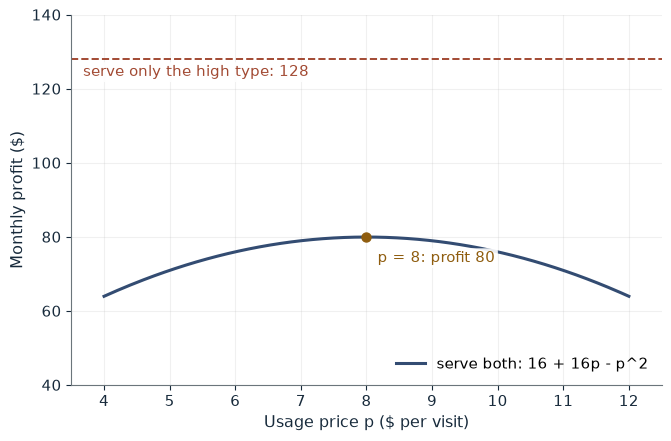

Membership fee F                   $8.00
High-type visits                   12
Low-type visits                    4
Profit serving both                $80.00
Profit serving only the high type  $128.00

Worked steps:
  1. F = (12 - 8)^2 / 2 = 8.00
  2. Visits: 20 - 8 = 12 and 12 - 8 = 4
  3. Fees 2 x 8.00 = 16.00; usage margin (8 - 4) x 16 = 64.00
  4. Profit = 16.00 + 64.00 = 80.00
  5. Compare with 128 from the high type alone

Keeping the low type requires F = (12 - 8)^2 / 2 = 8.00. Fees bring 16.00 and the usage margin (8 - 4) x 16 brings 64.00, for 80.00. This is the best inclusive tariff. Serving only the high type at F = 128 and p = 4 earns 128, more than any inclusive tariff.


In [2]:
show(tariff_picture(p=8))

Change one input, `p`, and hold the others at the book's values:

In [3]:
sweep(tariff_picture, 'p', [4, 6, 8, 12], {}, ['Membership fee F', 'Profit serving both'])

p | Membership fee F | Profit serving both
4 | $32.00 | $64.00
6 | $18.00 | $76.00
8 | $8.00 | $80.00
12 | $0.00 | $64.00


The best inclusive tariff is p = 8 with F = 8, earning \$80; serving only the high type at F = 128 and p = 4 earns \$128.

## 2. Versioning: how much to damage the basic tier

Types value quality at 4 and 10 and quality costs $q^2/2$. With the premium quality at 10, profit is

$$50-2q_L-\frac{q_L^2}{2}$$

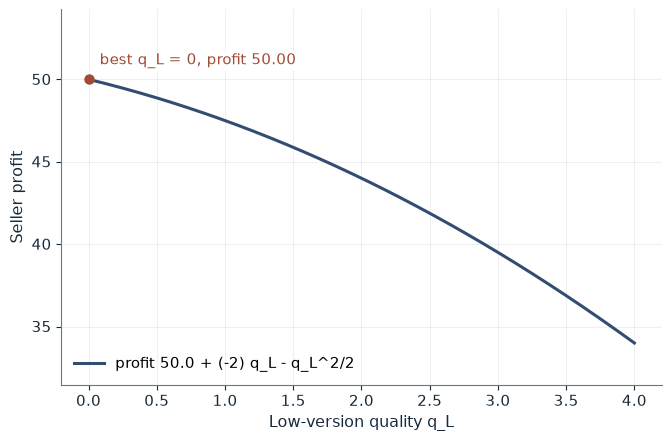

Low-version quality q_L       0
Low payment t_L               0.00
Premium payment t_H           100.00
High type's information rent  0.00
Seller profit                 50.00

Worked steps:
  1. Profit = 10^2 / 2 + (8 - 10) q_L - q_L^2 / 2
  2. Slope at zero is -2, so q_L = max(0, -2) = 0
  3. t_L = 4 x 0 = 0.00; t_H = 10^2 - 6 x 0 = 100.00
  4. Profit = 50.00 + (-2) x 0 - 0.00 = 50.00

With theta_H = 10, profit is 50.00 + (-2) q_L - q_L^2/2, maximized at q_L = 0. Payments are t_L = 0.00 and t_H = 100.00, and profit is 50.00. Each unit of low quality saves at least as much high-type rent as it earns from the low type, so no useful low version is offered.


In [4]:
show(versioning_picture(theta_h=10))

Change one input, `theta_h`, and hold the others at the book's values:

In [5]:
sweep(versioning_picture, 'theta_h', [6, 7, 8, 10], {}, ['Low-version quality q_L', 'Seller profit'])

theta_h | Low-version quality q_L | Seller profit
6 | 2 | 20.00
7 | 1 | 25.00
8 | 0 | 32.00
10 | 0 | 50.00


With a wide gap the seller offers no useful low version. With theta_H = 6 profit is $18+2q_L-q_L^2/2$, so the low version has quality 2 and payments are 8 and 32.

## 3. Bundling and correlated values

Ada values the tools at 90 and 30, Ben at 30 and 90. Separate prices of 90 earn

$$90+90=\$180$$

while a bundle at 120 sells to both: $120(2)=\$240$.

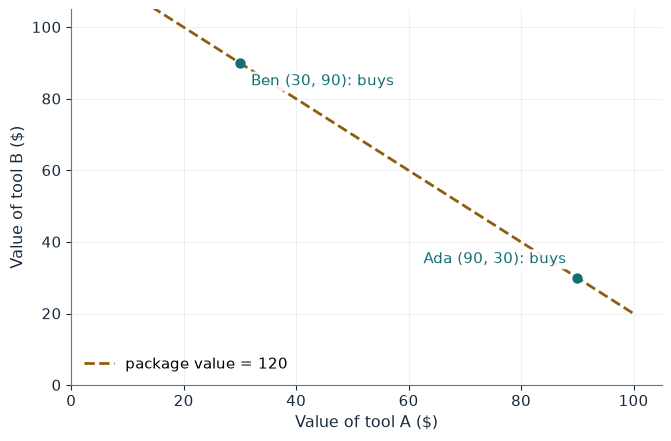

Best separate revenue  $180
Bundle buyers          2
Bundle revenue         $240

Worked steps:
  1. Package values: 90 + 30 = 120 and 30 + 90 = 120
  2. Buyers at 120: 2, revenue 120 x 2 = 240
  3. Best separate prices earn 180

Ada values the pair at 90 + 30 = 120 and Ben at 30 + 90 = 120. At a bundle price of 120, 2 of 2 buy and revenue is 120 x 2 = 240, more than the best separate revenue 180.


In [6]:
show(bundling_picture(pattern='offsetting', pb=120))

Change one input, `pb`, and hold the others at the book's values:

In [7]:
sweep(bundling_picture, 'pb', [60, 120, 150, 180], {'pattern': 'aligned'}, ['Best separate revenue', 'Bundle revenue'])

pb | Best separate revenue | Bundle revenue
60 | $180 | $120
120 | $180 | $120
150 | $180 | $150
180 | $180 | $180


With offsetting values the bundle earns \$240 against \$180. With aligned values (the sweep) the best bundle earns \$180, the same as separate prices.

## 4. Lerner rule and residual demand

Demand is $P=100-0.5Q$ and marginal cost \$20, so $Q=80$ and $P=60$.

$$L=\frac{60-20}{60}=\frac{2}{3}, \qquad \varepsilon=(-2)\frac{60}{80}=-1.5$$

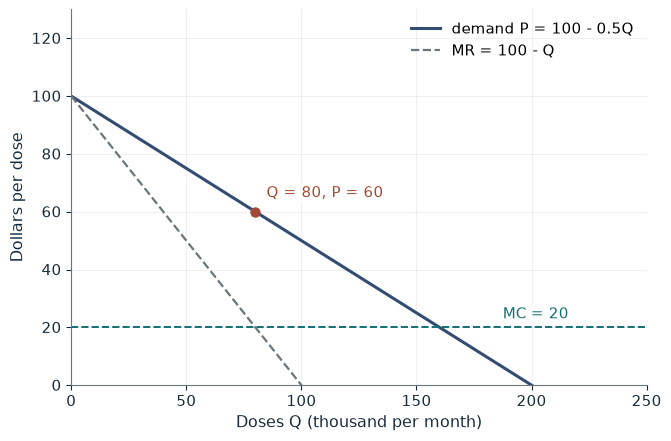

Quantity Q (thousand)         80
Price P                       $60.00
Lerner index L                0.667
Elasticity                    -1.500
1 / |elasticity|              0.667
Operating profit ($ million)  3.20

Worked steps:
  1. MR = MC: 100 - Q = 20, so Q = 80
  2. P = 100 - 0.5 x 80 = 60
  3. L = (60 - 20) / 60 = 0.667
  4. epsilon = (-2) x 60 / 80 = -1.500, so 1/|epsilon| = 0.667
  5. Profit = (60 - 20) x 80,000 = 3.20 million

Setting MR = MC gives Q = 100 - 20 = 80 thousand and P = 60. The Lerner index is (60 - 20) / 60 = 0.667, equal to 1/|epsilon| with epsilon = -1.500. Operating profit is 3.20 million.


In [8]:
show(lerner_picture(a=100, c=20))

Change one input, `a`, and hold the others at the book's values:

In [9]:
sweep(lerner_picture, 'a', [80, 90, 100, 120], {'c': 20}, ['Price P', 'Lerner index L', '1 / |elasticity|'])

a | Price P | Lerner index L | 1 / |elasticity|
80 | $50.00 | 0.600 | 0.600
90 | $55.00 | 0.636 | 0.636
100 | $60.00 | 0.667 | 0.667
120 | $70.00 | 0.714 | 0.714


The Lerner index equals one over the absolute elasticity in every case; a substitute that lowers the intercept to 80 cuts it from 0.667 to 0.600.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

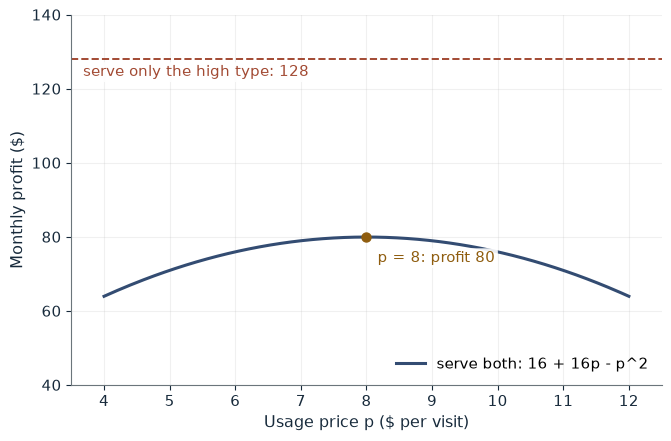

Membership fee F                   $8.00
High-type visits                   12
Low-type visits                    4
Profit serving both                $80.00
Profit serving only the high type  $128.00

Worked steps:
  1. F = (12 - 8)^2 / 2 = 8.00
  2. Visits: 20 - 8 = 12 and 12 - 8 = 4
  3. Fees 2 x 8.00 = 16.00; usage margin (8 - 4) x 16 = 64.00
  4. Profit = 16.00 + 64.00 = 80.00
  5. Compare with 128 from the high type alone

Keeping the low type requires F = (12 - 8)^2 / 2 = 8.00. Fees bring 16.00 and the usage margin (8 - 4) x 16 brings 64.00, for 80.00. This is the best inclusive tariff. Serving only the high type at F = 128 and p = 4 earns 128, more than any inclusive tariff.


In [10]:
show(tariff_picture(p=8))

## Practice

**1.** At a usage price of 6, what fee and profit result?

<details><summary>Answer</summary>

F = (12 - 6)^2 / 2 = 18; profit = 16 + 96 - 36 = 76.

</details>

**2.** At theta_H = 7, what low quality is offered?

<details><summary>Answer</summary>

Profit = 24.5 + q_L - q_L^2/2, maximized at q_L = 1 with profit 25.

</details>

**3.** At a demand intercept of 120 and marginal cost 40, what are P and L?

<details><summary>Answer</summary>

Q = 120 - 40 = 80, P = 120 - 40 = 80, L = 40/80 = 0.5.

</details>